# Explicación del framework  

**`rfi_framework_v4.py`**

Este cuaderno reproduce el módulo
`rfi_framework_v4.py`.

## Contexto

El receptor del radiotelescopio se alimenta de una antena de banda ancha y
mide densidad de flujo solar a 8800 MHz (banda X), muestreada tras la
detección a 1 Hz. Toda la contaminación se suma en el dominio de potencia.

## Las cuatro categorías de contaminación

| # | Categoría | Origen físico |
|---|-----------|---------------|
| 1 | `gaussian_noise`  | Ruido térmico (Johnson-Nyquist) del receptor — siempre presente |
| 2 | `clock_harmonics` | Armónicos de relojes digitales que alcanza la banda |
| 3 | `digital_radio`   | Emisiones de Wi-Fi / Bluetooth / 5G / celular |
| 4 | `radar`           | Radar pulsado dentro o cerca de la banda de observación |

De este modo, las tres primeras categorías inyectables (`clock_harmonics`,
`digital_radio`, `radar`) se añaden sobre la señal limpia, mientras que el ruido
térmico gaussiano constituye la base de la señal.

##  Importar Librerias

In [1]:
from __future__ import annotations

import copy
import warnings
from dataclasses import dataclass, field
from typing import Optional, Sequence

import numpy as np
from numpy.typing import NDArray
from scipy import signal as sp_signal
from scipy import stats as sp_stats

import matplotlib.pyplot as plt   # solo para las visualizaciones de este cuaderno

# ── Alias de tipos ────────────────────────────────────────────────────
Signal = NDArray[np.float64]
RNG = np.random.Generator

# ── Constantes de ventana / muestreo (idénticas al pipeline del proyecto)
N_FULL      = 300    # ventana completa: 5 min @ 1 Hz
SAMPLE_RATE = 1.0    # Hz (muestreo tras la detección)


##  Funciones importates

Funciones auxiliares de potencia y normalización que utilizan todos los
generadores y el motor de contaminación:

- **`_rms`** y **`_power`**: valor cuadrático medio y potencia media de una señal.
- **`sir_to_amplitude`**: dada una señal limpia y una relación señal-interferencia
  (SIR) objetivo en dB, devuelve la amplitud RMS que debe tener la
  interferencia para alcanzar esa SIR tras la mezcla. Se deriva de
  $\text{SIR}_{\text{dB}} = 10\log_{10}(P_{\text{señal}}/P_{\text{RFI}})$.
- **`_normalise`**: reescala una señal para que su RMS coincida con un objetivo.
- **`_rng`**: devuelve un generador aleatorio reproducible (acepta semilla o un
  generador ya existente).

In [2]:
def _rng(seed=None) -> RNG:
    if isinstance(seed, np.random.Generator):
        return seed
    return np.random.default_rng(seed)


def _rms(x: Signal) -> float:
    return float(np.sqrt(np.mean(x ** 2)))


def _power(x: Signal) -> float:
    return float(np.mean(x ** 2))


def sir_to_amplitude(clean: Signal, sir_db: float) -> float:
    """RMS amplitude an interference signal needs so the post-mix SIR is sir_db."""
    return float(np.sqrt(_power(clean) / 10.0 ** (sir_db / 10.0)))


def _normalise(sig: Signal, target_rms: float) -> Signal:
    """Scale sig so its RMS equals target_rms."""
    return sig * (target_rms / (_rms(sig) + 1e-30))

##  Ruido gaussiano

Ruido térmico de Johnson-Nyquist de la cadena receptora.

Se modela como ruido
blanco gaussiano.

El parámetro `amplitude_rel` expresa el RMS relativo al RMS de la señal limpia.

In [3]:
@dataclass
class GaussianNoiseParams:
    """Receiver thermal noise.
    """
    amplitude_rel: float = 0.02   # RMS relative to clean-signal RMS


def generate_gaussian_noise(n, sr, p, rng):
    return p.amplitude_rel * rng.standard_normal(n)

##  Armónicos de reloj digital

Los circuitos digitales
transportan señales de reloj periódicas cuya descomposición de Fourier es un
serie de armónicos. Para un reloj digital se modela como una señal trapezoidal (Paul 2022).



In [4]:
@dataclass
class ClockHarmonicsParams:
    """Comb of narrow lines from digital equipment harmonics.

    At 1 Hz sample rate, lines appear in the sub-Nyquist (0–0.5 Hz)
    band as beat frequencies after RF-to-baseband mixing.
    """
    fundamental_hz: float = 0.05      # comb fundamental in baseband
    num_harmonics: int = 5             # how many comb teeth
    rolloff_db_per_harmonic: float = 6.0
    amplitude_rel: float = 0.05
    phase_jitter_std: float = 0.02     # rad / s, slow drift
    amplitude_drift_rate: float = 0.0005


def generate_clock_harmonics(n, sr, p, rng):
    """Comb of integer-related sinusoids with geometric roll-off.

    Simplified Paul model: amplitude_n ∝ β^(n-1) where β is set by
    rolloff_db_per_harmonic. This captures the qualitative roll-off
    but not the breakpoint structure or duty-cycle nulls of Paul's
    full three-segment bound.
    """
    t = np.arange(n) / sr
    rfi = np.zeros(n)
    beta = 10.0 ** (-p.rolloff_db_per_harmonic / 20.0)

    for k in range(1, p.num_harmonics + 1):
        fk = p.fundamental_hz * k
        if fk > sr / 2:                # above Nyquist
            break
        amp_n = beta ** (k - 1)
        # slow phase wander
        phase_walk = np.cumsum(rng.normal(0, p.phase_jitter_std / sr, n))
        # slow amplitude drift
        amp_drift = np.clip(
            1.0 + p.amplitude_drift_rate * np.cumsum(rng.normal(0, 1.0, n)) / sr,
            0.5, 1.5,
        )
        rfi += amp_n * amp_drift * np.cos(
            2 * np.pi * fk * t + rng.uniform(0, 2 * np.pi) + phase_walk
        )

    return _normalise(rfi, p.amplitude_rel)

## Radio digital  (Wi-Fi / Bluetooth / 5G)

Los transmisores inalámbricos de consumo generan armónicos de
su portadora ($y = a_1x + a_2x^2 + a_3x^3 + \dots$). El término $x^k$ produce contenido en el armónico
$k$-ésimo, con ancho de banda $\approx k$ veces el original.

La estructura de paquetes (CSMA de Wi-Fi, FHSS de Bluetooth a 1600 saltos/s, tramas TDD de 5G de 5 ms) es mucho más rápida que la
integración de 1 s. Por lo tanto, a 1 Hz solo es visible la envolvente
del tráfico: un piso de ruido  más ráfagas
ocasionales cuando un dispositivo cercano transmite.

Se modela como ruido gaussiano limitado en
banda (filtro Butterworth pasa-banda + inclinación espectral), multiplicado por una envolvente de ráfagas con llegadas de
Poisson.

In [5]:
@dataclass
class DigitalRadioParams:
    """Wi-Fi / Bluetooth / 5G harmonics or spurious emissions reaching
    the observation band.

    Modeled in baseband as band-limited modulated noise plus an
    occasional packet-burst envelope to capture traffic dynamics.
    """
    bandwidth_hz: float = 0.20         # modulation bandwidth (post-detection)
    center_freq_hz: float = 0.15       # baseband center after RF-to-baseband mixing
    spectral_slope_db_oct: float = -2.0
    amplitude_rel: float = 0.05
    burst_rate_hz: float = 0.05        # packet-burst arrival rate
    burst_amplitude_factor: float = 2.5  # peak / baseline during burst
    burst_duration_s: float = 4.0      # mean duration of a traffic burst


def generate_digital_radio(n, sr, p, rng):
    """Continuous modulated baseband signal with occasional packet bursts.

    Captures the post-detection appearance of digital-radio harmonics:
    a persistent elevated noise floor from continuous traffic, plus
    occasional excursions when a nearby device transmits a long packet
    or stream.
    """
    # ── Continuous bandlimited modulated baseline ──
    white = rng.standard_normal(n)
    nyq = sr / 2.0
    lo = max((p.center_freq_hz - p.bandwidth_hz / 2) / nyq, 0.005)
    hi = min((p.center_freq_hz + p.bandwidth_hz / 2) / nyq, 0.999)
    if lo >= hi:
        lo, hi = 0.01, 0.99
    try:
        b, a = sp_signal.butter(4, [lo, hi], btype="band")
        baseline = sp_signal.lfilter(b, a, white)
    except ValueError:
        b, a = sp_signal.butter(4, min(hi, 0.99), btype="low")
        baseline = sp_signal.lfilter(b, a, white)

    # Spectral tilt (stability-guarded)
    if abs(p.spectral_slope_db_oct) > 0.1:
        coeff = np.clip(10.0 ** (p.spectral_slope_db_oct / 20.0) * 0.5, -0.99, 0.99)
        baseline = sp_signal.lfilter([1.0], [1.0, -coeff], baseline)

    baseline = _normalise(baseline, 1.0)  # unit-RMS for now

    # ── Traffic-burst envelope ──
    envelope = np.ones(n)
    duration_total = n / sr
    if p.burst_rate_hz > 1e-6:
        n_expected = int(p.burst_rate_hz * duration_total * 1.5) + 5
        arrivals = np.cumsum(
            rng.exponential(1.0 / p.burst_rate_hz, n_expected)
        )
        arrivals = arrivals[arrivals < duration_total]
        for t0 in arrivals:
            dur = max(rng.exponential(p.burst_duration_s), 1.0 / sr)
            i0 = int(t0 * sr)
            i1 = min(int((t0 + dur) * sr), n)
            if i1 > i0:
                # smooth raised-cosine attack/decay
                nb = i1 - i0
                env_b = np.ones(nb)
                rise = max(int(0.15 * nb), 1)
                env_b[:rise] = np.linspace(1.0, p.burst_amplitude_factor, rise)
                env_b[rise:] = p.burst_amplitude_factor
                fall = max(int(0.15 * nb), 1)
                env_b[-fall:] = np.linspace(p.burst_amplitude_factor, 1.0, fall)
                envelope[i0:i1] = np.maximum(envelope[i0:i1], env_b)

    rfi = baseline * envelope
    return _normalise(rfi, p.amplitude_rel)

## Radar dentro o cerca de la banda

La banda 8750–8850 MHz está asignada a título primario a
radiolocalización y radionavegación aeronáutica. Los radares transmiten pulsos
cortos de alta potencia (PRF de 200–5000 Hz, anchos de pulso de 0.1–100 µs).


Los pulsos individuales (µs) y los barridos
(~30 ms) no se resuelven a 1 Hz. Lo que sí es visible: eventos de
iluminación sostenida (tránsitos de aeronaves) de segundos
a minutos, que aparecen como una base de ruido elevada, modulación periódica del
barrido y picos de una sola muestra de trenes de pulsos muy fuertes.

Cada "ráfaga" representa un evento de iluminación sostenida.
Se modela con llegadas de Poisson, duración gaussiana y una envolvente
positiva. Por construcción, el radar aporta
potencia estrictamente positiva.

In [6]:
@dataclass
class RadarParams:
    """Pulsed-radar signature at 1 Hz post-detection.

    Each "burst" represents a sustained illumination event — an
    aircraft transit, close ducting, or a cluster of strong pulses
    spanning multiple seconds.
    """
    mean_burst_rate_hz: float = 0.03   # ~1-2 events / min (aircraft transits)
    mean_duration_s: float = 3.0       # typical sustained event
    duration_std_s: float = 1.0
    amplitude_rel: float = 0.35        # peak amplitude / signal RMS
    rise_time_fraction: float = 0.15   # attack as fraction of duration


def generate_radar(n, sr, p, rng):
    """Positive-definite envelope events at Poisson arrival times.

    Returns non-negative RFI (radar contributes positive power only).
    """
    rfi = np.zeros(n)
    duration = n / sr

    n_exp = int(p.mean_burst_rate_hz * duration * 1.5) + 10
    arrivals = np.cumsum(
        rng.exponential(1.0 / max(p.mean_burst_rate_hz, 1e-6), n_exp)
    )
    arrivals = arrivals[arrivals < duration]

    for t0 in arrivals:
        dur = max(rng.normal(p.mean_duration_s, p.duration_std_s), 0.5 / sr)
        amp = rng.exponential(1.0) * p.amplitude_rel
        i0 = int(t0 * sr)
        i1 = min(int((t0 + dur) * sr), n)
        if i0 >= n or i1 <= i0:
            continue
        nb = i1 - i0
        env = np.ones(nb)
        rise = max(int(p.rise_time_fraction * nb), 1)
        env[:rise] = np.linspace(0, 1, rise)
        fall = max(int(0.2 * nb), 1)
        env[-fall:] = np.linspace(1, 0, fall)
        rfi[i0:i1] += amp * env

    return rfi    # already positive-definite

## Registro de modelos y composición de escenarios

**`MODEL_REGISTRY`** asocia cada nombre de fuente a una tupla
`(función_generadora, clase_de_parámetros)`. Es el punto único de despacho.

**`ContaminationScenario`** agrupa una o más fuentes con su peso y una SIR
opcional. El método `add` valida el nombre contra el registro y, si no se pasan
parámetros, instancia los valores por defecto.

`contaminate` es el la logica central:
1. Genera cada componente y la escala por `weight × RMS_de_la_señal` (de ahí que
   los `amplitude_rel` sean **relativos**), sumándolas en `rfi_total`.
2. Si el escenario fija una SIR objetivo, reescala el total de RFI con
   `sir_to_amplitude` para alcanzarla exactamente.
3. Suma la RFI a la señal limpia.
4. Emite una advertencia de no negatividad si aparecen muestras negativas.
   
5. Devuelve un diccionario con la señal limpia, la contaminada, la RFI total,
   los componentes individuales.

In [7]:
MODEL_REGISTRY: dict[str, tuple] = {
    "gaussian_noise":   (generate_gaussian_noise,   GaussianNoiseParams),
    "clock_harmonics":  (generate_clock_harmonics,  ClockHarmonicsParams),
    "digital_radio":    (generate_digital_radio,    DigitalRadioParams),
    "radar":            (generate_radar,            RadarParams),
}


@dataclass
class ContaminationScenario:
    """One or more contamination models with weights and optional SIR."""
    models: list[tuple[str, object, float]] = field(default_factory=list)
    sir_db: Optional[float] = None
    name: str = "unnamed"

    def add(self, model_name: str, params=None, weight: float = 1.0):
        if model_name not in MODEL_REGISTRY:
            raise ValueError(
                f"Unknown model '{model_name}'. "
                f"Available: {list(MODEL_REGISTRY)}"
            )
        if params is None:
            params = MODEL_REGISTRY[model_name][1]()
        self.models.append((model_name, params, weight))
        return self


def contaminate(
    clean_signal: Signal,
    sample_rate: float,
    scenario: ContaminationScenario,
    seed=None,
) -> dict:
    """Apply scenario to clean signal.

    Returns dict with: clean, contaminated, rfi_total, rfi_components, metadata.
    """
    rng_gen = _rng(seed)
    n = len(clean_signal)
    sig_rms = _rms(clean_signal) + 1e-30

    components: dict[str, Signal] = {}
    rfi_total = np.zeros(n)
    for name, params, weight in scenario.models:
        gen_fn = MODEL_REGISTRY[name][0]
        comp = gen_fn(n, sample_rate, params, rng_gen) * weight * sig_rms
        components[name] = comp
        rfi_total += comp

    if scenario.sir_db is not None:
        target = sir_to_amplitude(clean_signal, scenario.sir_db)
        scale = target / (_rms(rfi_total) + 1e-30)
        rfi_total *= scale
        for k in components:
            components[k] *= scale

    contaminated = clean_signal + rfi_total

    # Non-negativity guard
    n_neg = int(np.sum(contaminated < 0))
    if n_neg > 0:
        warnings.warn(
            f"{n_neg} samples ({n_neg/n:.1%}) are negative — unphysical "
            f"for flux density. Raise SIR target or reduce amplitudes.",
            stacklevel=2,
        )

    sir_actual = 10 * np.log10(
        _power(clean_signal) / max(_power(rfi_total), 1e-30)
    )

    return {
        "clean": np.asarray(clean_signal),
        "contaminated": contaminated,
        "rfi_total": rfi_total,
        "rfi_components": components,
        "metadata": {
            "scenario_name": scenario.name,
            "sir_target_db": scenario.sir_db,
            "sir_actual_db": float(sir_actual),
            "sample_rate": sample_rate,
            "n_samples": n,
            "model_names": [m[0] for m in scenario.models],
            "signal_rms": sig_rms,
            "rfi_rms": float(_rms(rfi_total)),
            "n_negative_samples": n_neg,
        },
    }

## Generación y escenarios predefinidos

`generate_batch` aplica un escenario a cada señal
limpia de un conjunto.

Los escenarios predefinidos son combinaciones representativas:
`thermal_only` (solo ruido térmico), `clock_dominant`, `digital_radio`,
`radar_dominant` y `mixed_realistic` (las cuatro fuentes, lo más cercano a un
sitio real). `random_scenario` produce escenarios aleatorios para aumento de
datos de ML: SIR aleatoria, de 0 a 3 fuentes no térmicas elegidas al azar, y
ruido gaussiano siempre incluido.

In [8]:
def generate_batch(clean_signals, sample_rate, scenario_factory, base_seed=42):
    """Apply a (possibly random) scenario to each clean signal."""
    results = []
    for i, clean in enumerate(clean_signals):
        r = _rng(base_seed + i)
        result = contaminate(clean, sample_rate, scenario_factory(i, r), seed=r)
        result["metadata"]["batch_index"] = i
        results.append(result)
    return results


def scenario_thermal_only(sir_db=30.0) -> ContaminationScenario:
    """Control scenario — just thermal noise. Used as baseline."""
    s = ContaminationScenario(name="thermal_only", sir_db=sir_db)
    s.add("gaussian_noise", GaussianNoiseParams(amplitude_rel=0.01))
    return s


def scenario_clock_dominant(sir_db=15.0) -> ContaminationScenario:
    """Self-RFI dominant — clock harmonics + thermal noise."""
    s = ContaminationScenario(name="clock_dominant", sir_db=sir_db)
    s.add("clock_harmonics", ClockHarmonicsParams(
        fundamental_hz=0.06, num_harmonics=5, amplitude_rel=0.06,
    ))
    s.add("gaussian_noise", GaussianNoiseParams(amplitude_rel=0.02))
    return s


def scenario_digital_radio(sir_db=12.0) -> ContaminationScenario:
    """Cellular / Wi-Fi nearby — modulated baseline + traffic bursts."""
    s = ContaminationScenario(name="digital_radio", sir_db=sir_db)
    s.add("digital_radio", DigitalRadioParams(amplitude_rel=0.07))
    s.add("gaussian_noise", GaussianNoiseParams(amplitude_rel=0.02))
    return s


def scenario_radar_dominant(sir_db=10.0) -> ContaminationScenario:
    """X-band radar dominant — pulsed events + thermal noise."""
    s = ContaminationScenario(name="radar_dominant", sir_db=sir_db)
    s.add("radar", RadarParams(
        mean_burst_rate_hz=0.05, mean_duration_s=3.0, amplitude_rel=0.4,
    ))
    s.add("gaussian_noise", GaussianNoiseParams(amplitude_rel=0.02))
    return s


def scenario_mixed_realistic(sir_db=8.0) -> ContaminationScenario:
    """All four sources, moderately strong. Closest to a real site."""
    s = ContaminationScenario(name="mixed_realistic", sir_db=sir_db)
    s.add("clock_harmonics", ClockHarmonicsParams(amplitude_rel=0.04), weight=0.5)
    s.add("digital_radio", DigitalRadioParams(amplitude_rel=0.05), weight=0.7)
    s.add("radar", RadarParams(amplitude_rel=0.35), weight=1.0)
    s.add("gaussian_noise", GaussianNoiseParams(amplitude_rel=0.02))
    return s


def random_scenario(rng_gen, sir_range=(3.0, 25.0), max_models=3) -> ContaminationScenario:
    """Random scenario for ML data augmentation."""
    sir = rng_gen.uniform(*sir_range)
    # Always include gaussian noise; pick 0-3 other models
    non_noise = ["clock_harmonics", "digital_radio", "radar"]
    k = rng_gen.integers(0, min(max_models, len(non_noise)) + 1)
    chosen = list(rng_gen.choice(non_noise, size=k, replace=False)) if k > 0 else []

    s = ContaminationScenario(name="random", sir_db=sir)
    for name in chosen:
        params = MODEL_REGISTRY[name][1]()
        if hasattr(params, "amplitude_rel"):
            params.amplitude_rel *= rng_gen.uniform(0.5, 1.5)
        s.add(name, params, weight=rng_gen.uniform(0.3, 1.5))
    s.add("gaussian_noise", GaussianNoiseParams(amplitude_rel=rng_gen.uniform(0.01, 0.03)))
    return s

In [18]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Validación estadística y Utilidades para graficar

**`ValidationReport` / `validate`** comparan dos señales (típicamente limpia vs.
contaminada) mediante momentos (media, desviación, asimetría, curtosis), la
prueba de Kolmogorov-Smirnov, la distancia de Wasserstein, la correlación de sus
densidades espectrales de potencia (Welch) y el factor de cresta.

**`plot_summary` / `plot_components`** son las utilidades de graficado propias del
módulo (panel resumen y panel por componente). **`demo`** es la prueba de humo
autocontenida del módulo. Se incluyen aquí **sin modificar** para preservar la
equivalencia con el original;

In [9]:
@dataclass
class ValidationReport:
    label_a: str = ""
    label_b: str = ""
    mean_a: float = 0.0;  mean_b: float = 0.0
    std_a: float = 0.0;   std_b: float = 0.0
    skew_a: float = 0.0;  skew_b: float = 0.0
    kurt_a: float = 0.0;  kurt_b: float = 0.0
    ks_stat: float = 0.0; ks_p: float = 0.0
    wasserstein: float = 0.0
    psd_corr: float = 0.0
    crest_a: float = 0.0; crest_b: float = 0.0

    def summary(self) -> str:
        return "\n".join([
            f"Validation: {self.label_a} vs {self.label_b}",
            f"  Mean      {self.mean_a:+.4f}  /  {self.mean_b:+.4f}",
            f"  Std       {self.std_a:.4f}   /  {self.std_b:.4f}",
            f"  Skewness  {self.skew_a:.3f}   /  {self.skew_b:.3f}",
            f"  Kurtosis  {self.kurt_a:.3f}   /  {self.kurt_b:.3f}",
            f"  KS stat   {self.ks_stat:.4f}  (p = {self.ks_p:.4f})",
            f"  Wass.     {self.wasserstein:.4f}",
            f"  PSD corr  {self.psd_corr:.3f}",
            f"  Crest     {self.crest_a:.2f}   /  {self.crest_b:.2f}",
        ])


def validate(a, b, sr, label_a="Clean", label_b="Contaminated"):
    r = ValidationReport(label_a=label_a, label_b=label_b)
    r.mean_a, r.mean_b = float(np.mean(a)), float(np.mean(b))
    r.std_a,  r.std_b  = float(np.std(a)),  float(np.std(b))
    r.skew_a, r.skew_b = float(sp_stats.skew(a)), float(sp_stats.skew(b))
    r.kurt_a, r.kurt_b = float(sp_stats.kurtosis(a)), float(sp_stats.kurtosis(b))
    ks, kp = sp_stats.ks_2samp(a, b)
    r.ks_stat, r.ks_p = float(ks), float(kp)
    r.wasserstein = float(sp_stats.wasserstein_distance(a, b))

    nperseg = min(256, len(a))
    _, pa = sp_signal.welch(a, fs=sr, nperseg=nperseg)
    _, pb = sp_signal.welch(b, fs=sr, nperseg=nperseg)
    m = min(len(pa), len(pb))
    la, lb = np.log10(pa[:m] + 1e-30), np.log10(pb[:m] + 1e-30)
    if np.std(la) > 1e-10 and np.std(lb) > 1e-10:
        r.psd_corr = float(np.corrcoef(la, lb)[0, 1])

    r.crest_a = float(np.max(np.abs(a)) / (_rms(a) + 1e-30))
    r.crest_b = float(np.max(np.abs(b)) / (_rms(b) + 1e-30))
    return r


def plot_summary(result, figsize=(13, 9)):
    """Four-panel overview: clean+contam, RFI, PSD, histogram."""
    import matplotlib.pyplot as plt
    c, x, rfi = result["clean"], result["contaminated"], result["rfi_total"]
    sr = result["metadata"]["sample_rate"]
    t = np.arange(len(c)) / sr
    meta = result["metadata"]

    fig, ax = plt.subplots(2, 2, figsize=figsize)
    fig.suptitle(f"{meta['scenario_name']}   SIR = {meta['sir_actual_db']:.1f} dB",
                 fontsize=12)

    ax[0,0].plot(t, c, lw=0.6, alpha=.7, label="Clean")
    ax[0,0].plot(t, x, lw=0.6, alpha=.7, label="Contam.")
    ax[0,0].set(xlabel="Time (s)", ylabel="Flux density", title="Time series")
    ax[0,0].legend(fontsize=8)

    ax[0,1].plot(t, rfi, lw=0.6, color="C3")
    ax[0,1].set(xlabel="Time (s)", ylabel="RFI", title="Total RFI")

    for sig, lab in [(c, "Clean"), (x, "Contam.")]:
        f, p = sp_signal.welch(sig, fs=sr, nperseg=min(256, len(sig)))
        ax[1,0].semilogy(f, p, lw=.8, alpha=.7, label=lab)
    ax[1,0].set(xlabel="Freq (Hz)", ylabel="PSD", title="PSD")
    ax[1,0].legend(fontsize=8)

    ax[1,1].hist(c, bins=60, alpha=.5, density=True, label="Clean")
    ax[1,1].hist(x, bins=60, alpha=.5, density=True, label="Contam.")
    ax[1,1].set(xlabel="Flux density", ylabel="Density", title="Amplitude dist.")
    ax[1,1].legend(fontsize=8)

    plt.tight_layout()
    return fig


def plot_components(result, figsize=(13, 7)):
    """One subplot per RFI component."""
    import matplotlib.pyplot as plt
    comps = result["rfi_components"]
    sr = result["metadata"]["sample_rate"]
    n = len(result["clean"])
    t = np.arange(n) / sr
    nc = len(comps)
    if nc == 0:
        return None
    fig, axes = plt.subplots(nc, 1, figsize=(figsize[0], 2.2 * nc), sharex=True)
    if nc == 1:
        axes = [axes]
    for ax, (name, comp) in zip(axes, comps.items()):
        ax.plot(t, comp, lw=0.5)
        ax.set_ylabel(name, fontsize=9)
        ax.text(.98, .85, f"RMS {_rms(comp):.2e}", transform=ax.transAxes,
                fontsize=8, ha="right",
                bbox=dict(boxstyle="round,pad=.2", fc="wheat", alpha=.5))
    axes[-1].set_xlabel("Time (s)")
    fig.suptitle("RFI Components", fontsize=11)
    plt.tight_layout()
    return fig


def demo(n_samples=60, sample_rate=1.0, seed=42):
    """Self-contained smoke test for the 1-minute / 1 Hz configuration."""
    rng = _rng(seed)
    t = np.arange(n_samples) / sample_rate
    clean = 150.0 + 3.0 * np.sin(2*np.pi*0.005*t) + rng.normal(0, 0.4, n_samples)

    print("RFI Framework v4 — Demo")
    print(f"  {n_samples} samples @ {sample_rate} Hz "
          f"({n_samples/sample_rate:.0f} s window)\n")

    for factory in [scenario_thermal_only, scenario_clock_dominant,
                    scenario_digital_radio, scenario_radar_dominant,
                    scenario_mixed_realistic]:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            res = contaminate(clean, sample_rate, factory(), seed=rng)
        m = res["metadata"]
        print(f"  {m['scenario_name']:18s}  SIR={m['sir_actual_db']:6.1f} dB  "
              f"neg={m['n_negative_samples']:3d}  models={m['model_names']}")

    print("\nValidation (mixed_realistic):")
    rep = validate(clean, res["contaminated"], sample_rate)
    print(rep.summary())
    return res


# Prueba de humo del módulo (idéntica al bloque __main__ original)
_ = demo()

RFI Framework v4 — Demo
  60 samples @ 1.0 Hz (60 s window)

  thermal_only        SIR=  30.0 dB  neg=  0  models=['gaussian_noise']
  clock_dominant      SIR=  15.0 dB  neg=  0  models=['clock_harmonics', 'gaussian_noise']
  digital_radio       SIR=  12.0 dB  neg=  0  models=['digital_radio', 'gaussian_noise']
  radar_dominant      SIR=  10.0 dB  neg=  0  models=['radar', 'gaussian_noise']
  mixed_realistic     SIR=   8.0 dB  neg=  0  models=['clock_harmonics', 'digital_radio', 'radar', 'gaussian_noise']

Validation (mixed_realistic):
Validation: Clean vs Contaminated
  Mean      +152.0855  /  +146.7938
  Std       1.0272   /  60.3159
  Skewness  -0.733   /  0.401
  Kurtosis  -0.474   /  0.087
  KS stat   0.5833  (p = 0.0000)
  Wass.     45.4504
  PSD corr  0.029
  Crest     1.01   /  2.04


## Representación CWT (escalograma de Morlet, 32 escalas)

Se agregan las visualizaciones solicitadas, el comportamiento
de cada fuente en el dominio del tiempo y su CWT. De este modo, lo que se observa aquí
es la misma representación tiempo-escala que recibe la primera etapa del sistema.

In [10]:
# ── CWT scalogram (Morlet, reflection padding) — idéntica al notebook del clasificador
def _morlet(M, s, w=5.0):
    xs = (np.arange(M) - (M - 1) / 2) / s
    return np.exp(1j*w*xs) * np.exp(-0.5*xs*xs) * (np.pi**-0.25)

def _cwt(data, widths, w=5.0):
    n = len(data)
    out = np.empty((len(widths), n), dtype=np.complex128)
    for i, s in enumerate(widths):
        M = min(int(10 * s + 1) | 1, n)
        wav = _morlet(M, s, w)
        out[i] = np.convolve(data, np.conj(wav[::-1]), mode="same")
    return out

CWT_SCALES = 32

def make_scalogram(sig: np.ndarray, n_scales: int = CWT_SCALES, pad: int = 20):
    """(n,) → (n_scales, n) float32 log-normalised to [0,1]."""
    n = len(sig)
    padded = np.pad(sig, pad, mode="reflect")
    widths = np.geomspace(1, n // 2, num=n_scales)
    coefs = _cwt(padded, widths)
    mag = np.abs(coefs[:, pad:pad+n]).astype(np.float32)
    mag = np.log1p(mag)
    lo, hi = mag.min(), mag.max()
    if hi - lo > 1e-8:
        mag = (mag - lo) / (hi - lo)
    return mag


# ── Helper de visualización (dominio del tiempo + escalograma CWT) ──
def show_time_and_cwt(sig, sr=SAMPLE_RATE, title="", carrier=None):
    sig = np.asarray(sig, dtype=np.float64)
    t = np.arange(len(sig)) / sr
    scal = make_scalogram(sig)

    fig, (axt, axc) = plt.subplots(1, 2, figsize=(13, 4))

    axt.plot(t, sig, lw=0.9, color="C0")
    if carrier is not None:
        axt.axhline(carrier, ls="--", lw=0.9, color="0.6", label="portadora plana")
        axt.legend(fontsize=8, loc="upper right")
    axt.set(xlabel="Tiempo (s)", ylabel="Densidad de flujo (SFU)",
            title=f"{title} — dominio del tiempo")
    axt.grid(alpha=0.25)

    im = axc.imshow(scal, aspect="auto", origin="lower", cmap="magma",
                    extent=[0, len(sig)/sr, 0, CWT_SCALES])
    axc.set(xlabel="Tiempo (s)",
            ylabel="Índice de escala  (↑ = menor frecuencia)",
            title=f"{title} — escalograma CWT (Morlet, {CWT_SCALES} escalas)")
    fig.colorbar(im, ax=axc, fraction=0.046, pad=0.04, label="magnitud norm.")

    plt.tight_layout()
    return fig

###  Montaje de las demostraciones aisladas

In [11]:
def build_isolated(model_name, params=None, seed=0,
                   carrier_val=150.0, n=N_FULL):
    """Synthesise ONE RFI source in isolation on a flat carrier."""
    carrier = np.full(n, carrier_val, dtype=np.float64)
    sc = ContaminationScenario(name=f"{model_name}_isolated")  # sir_db=None
    sc.add(model_name, params)
    return contaminate(carrier, SAMPLE_RATE, sc, seed=seed)

CARRIER = 150.0   # SFU — portadora plana de referencia
print(f"Portadora plana: {CARRIER} SFU sobre {N_FULL} muestras "
      f"({N_FULL/SAMPLE_RATE/60:.0f} min @ {SAMPLE_RATE} Hz)")

Portadora plana: 150.0 SFU sobre 300 muestras (5 min @ 1.0 Hz)


###  Ruido gaussiano aislado

RFI RMS = 7.217 SFU   |   SIR efectiva = 26.4 dB


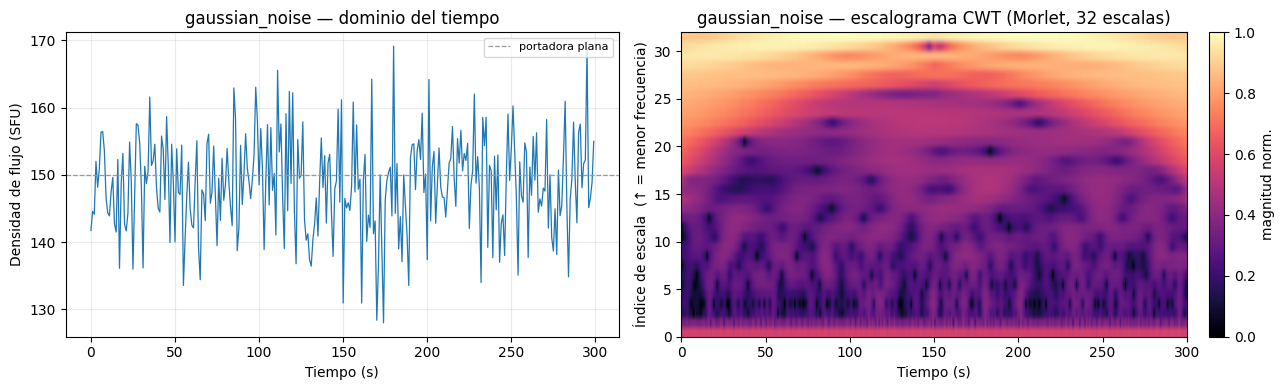

In [12]:
res = build_isolated("gaussian_noise", GaussianNoiseParams(amplitude_rel=0.05), seed=10)
m = res["metadata"]
print(f"RFI RMS = {m['rfi_rms']:.3f} SFU   |   SIR efectiva = {m['sir_actual_db']:.1f} dB")
show_time_and_cwt(res["contaminated"], title="gaussian_noise", carrier=CARRIER)
plt.show()

### Armónicos de reloj aislados



RFI RMS = 7.500 SFU   |   SIR efectiva = 26.0 dB


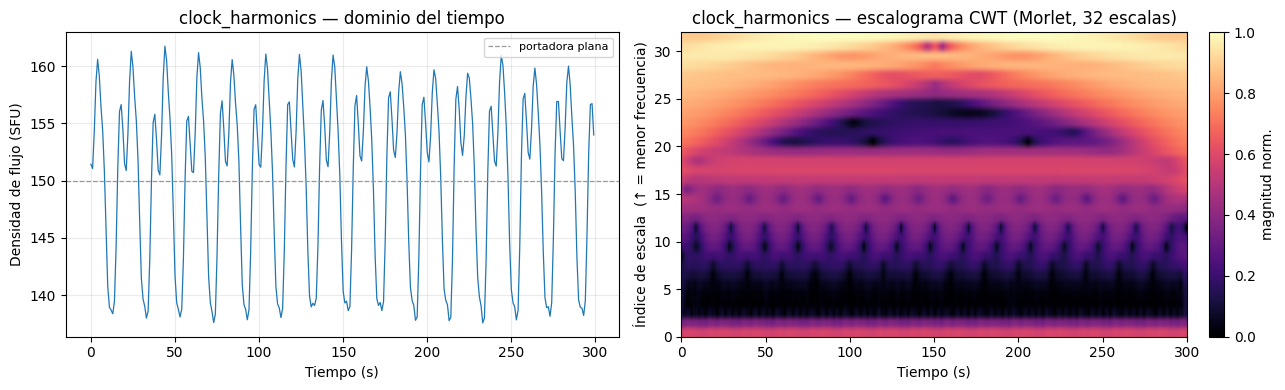

In [13]:
res = build_isolated("clock_harmonics", ClockHarmonicsParams(amplitude_rel=0.05), seed=11)
m = res["metadata"]
print(f"RFI RMS = {m['rfi_rms']:.3f} SFU   |   SIR efectiva = {m['sir_actual_db']:.1f} dB")
show_time_and_cwt(res["contaminated"], title="clock_harmonics", carrier=CARRIER)
plt.show()

### Radio digital aislada


RFI RMS = 10.500 SFU   |   SIR efectiva = 23.1 dB


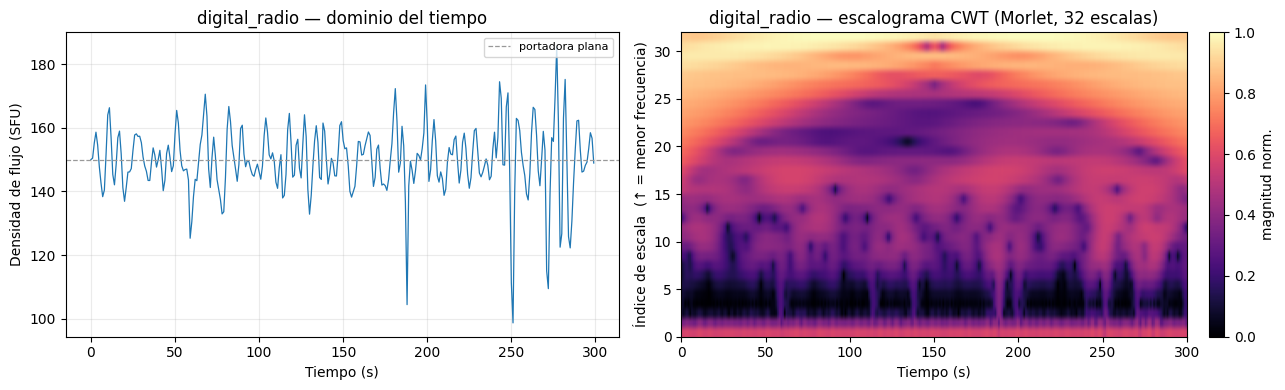

In [14]:
res = build_isolated("digital_radio", DigitalRadioParams(amplitude_rel=0.07), seed=12)
m = res["metadata"]
print(f"RFI RMS = {m['rfi_rms']:.3f} SFU   |   SIR efectiva = {m['sir_actual_db']:.1f} dB")
show_time_and_cwt(res["contaminated"], title="digital_radio", carrier=CARRIER)
plt.show()

### Radar aislado

RFI RMS = 11.427 SFU   |   SIR efectiva = 22.4 dB   |   muestras negativas = 0


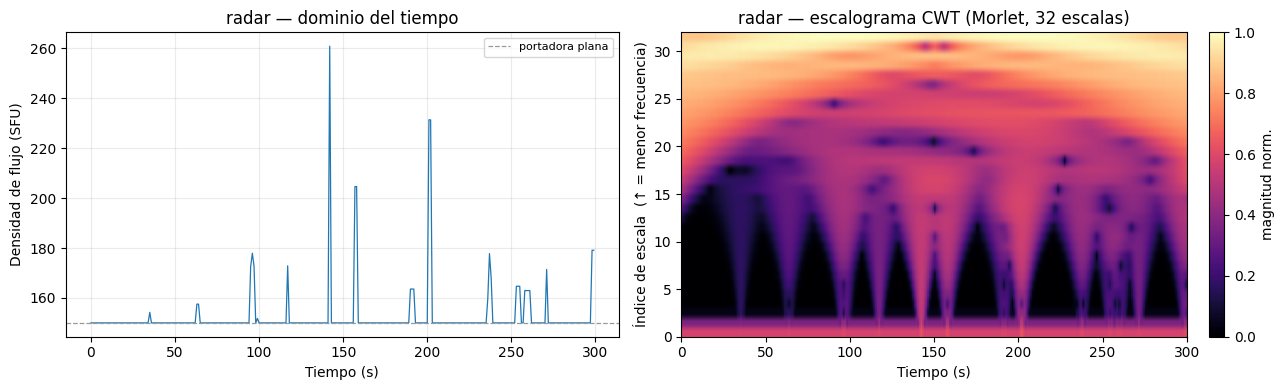

In [15]:
res = build_isolated("radar", RadarParams(amplitude_rel=0.35, mean_burst_rate_hz=0.05), seed=13)
m = res["metadata"]
print(f"RFI RMS = {m['rfi_rms']:.3f} SFU   |   SIR efectiva = {m['sir_actual_db']:.1f} dB   "
      f"|   muestras negativas = {m['n_negative_samples']}")
show_time_and_cwt(res["contaminated"], title="radar", carrier=CARRIER)
plt.show()

## Escenario combinado

Escenario: mixed_realistic
  Fuentes:        ['clock_harmonics', 'digital_radio', 'radar', 'gaussian_noise']
  SIR objetivo:   8.0 dB   |   SIR efectiva: 8.0 dB
  RFI RMS:        59.716 SFU
  Muestras neg.:  0



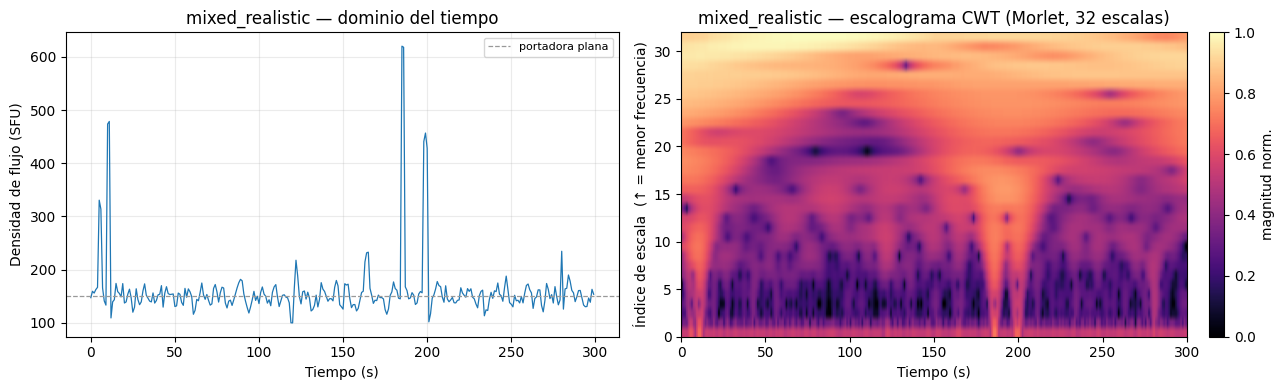

Validation: Portadora vs Contaminada
  Mean      +150.0000  /  +159.3922
  Std       0.0000   /  58.9728
  Skewness  nan   /  5.424
  Kurtosis  nan   /  33.015
  KS stat   0.5100  (p = 0.0000)
  Wass.     22.7112
  PSD corr  0.000
  Crest     1.00   /  3.65


/tmp/ipykernel_2875/418291519.py:32: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  r.skew_a, r.skew_b = float(sp_stats.skew(a)), float(sp_stats.skew(b))
/tmp/ipykernel_2875/418291519.py:33: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  r.kurt_a, r.kurt_b = float(sp_stats.kurtosis(a)), float(sp_stats.kurtosis(b))


In [16]:
carrier = np.full(N_FULL, CARRIER, dtype=np.float64)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    res = contaminate(carrier, SAMPLE_RATE, scenario_mixed_realistic(sir_db=8.0), seed=7)

m = res["metadata"]
print(f"Escenario: {m['scenario_name']}")
print(f"  Fuentes:        {m['model_names']}")
print(f"  SIR objetivo:   {m['sir_target_db']:.1f} dB   |   SIR efectiva: {m['sir_actual_db']:.1f} dB")
print(f"  RFI RMS:        {m['rfi_rms']:.3f} SFU")
print(f"  Muestras neg.:  {m['n_negative_samples']}")
print()

show_time_and_cwt(res["contaminated"], title="mixed_realistic", carrier=CARRIER)
plt.show()

# Reporte de validación estadística (portadora vs. contaminada)
print(validate(res["clean"], res["contaminated"], SAMPLE_RATE,
               label_a="Portadora", label_b="Contaminada").summary())